# Learning unknown graphlike detector supports

This walkthrough uses the independent THeatA DEM from a distance-3 Stim
surface-code memory experiment. It considers every detector singleton and
pair. The detector-only fit uses calibration detections. A separate optional
stage uses calibration logical outcomes to attach L0 labels to the fixed
detector fits. The evaluation stage compares support, priors, labels, and
decoding against the simulation reference with independent heldout shots.

Run the project setup script and select the **THeatA prior calibration**
kernel. The configuration uses two nested calibration prefixes and the same
10,000 heldout shots for each decoder.


In [1]:
from pathlib import Path
import json

import numpy as np
from IPython.display import Markdown, Image, display

from theata_prior.candidates import DetectorMetadata
from theata_prior.io import read_json
from theata_prior.structure_config import load_structure_config
from theata_prior import structure_experiment as experiment

cwd = Path.cwd().resolve()
root = next((path for path in (cwd, *cwd.parents)
             if (path / 'configs/structure_smoke.yaml').is_file()), None)
if root is None:
    raise RuntimeError('Open Jupyter from within the calibration project.')
config = load_structure_config(root / 'configs/structure1.yaml')
out = root / 'results/structure1'
print(json.dumps(experiment.preflight_structure(config), indent=2))


[
  {
    "distance": 5,
    "rounds": 5,
    "detectors": 72,
    "pairs": 2556,
    "candidates": 2628,
    "float64_moment_bytes": 41472,
    "working_array_budget_bytes": 39407616,
    "memmap_sample_bytes_per_rate": 29200000,
    "moment_multiply_accumulates_per_max_prefix": 518400000
  },
  {
    "distance": 7,
    "rounds": 7,
    "detectors": 192,
    "pairs": 18336,
    "candidates": 18528,
    "float64_moment_bytes": 294912,
    "working_array_budget_bytes": 112459776,
    "memmap_sample_bytes_per_rate": 77200000,
    "moment_multiply_accumulates_per_max_prefix": 3686400000
  }
]


## Detector-only support and prior fit

Build and sample the independent DEM. The compiler and sampler archive their
simulation inputs. The fitter receives the sanitized detector map and the
calibration detector arrays. Fisher tests and Holm correction screen all
pair candidates. Complete-family singleton residuals and their influence
standard errors determine the singleton screen. The selected model refits
rates on that support.


In [2]:
experiment.build_structure(config, out)
experiment.sample_structure(config, out)
experiment.fit_structure_stage(config, out)

metadata_path = next((out / 'blind').glob('d*/p*/detector_metadata.json'))
metadata = DetectorMetadata.from_dict(read_json(metadata_path))
n = max(config.base.training_shots)
fit_dir = metadata_path.parent / f'rep000_n{n}'
fit_status = read_json(fit_dir / 'fit.json')
print('Fit status', fit_status['status'])
with np.load(fit_dir / 'detector_fit.npz') as fit:
    print('Raw S11 block, local detectors 0 through 3')
    print(np.round(fit['raw_p_ij'][:4, :4], 5))
    if 'complete_selected_active' in fit:
        active = np.flatnonzero(fit['complete_selected_active'])
        print('First ten final active supports and priors')
        print([(metadata.candidates.support(i), round(float(fit['complete_selected_priors'][i]), 6))
               for i in active[:10]])
        print('Detector-marginal DEM', (fit_dir / 'complete_selected_detector_only.dem').relative_to(out))


build: d=5 compiling THeatA model
build: d=5 p=0.001; 72 detectors, 301 identifiable edges
build: d=5 p=0.002; 72 detectors, 301 identifiable edges
build: d=5 p=0.004; 72 detectors, 301 identifiable edges
build: d=7 compiling THeatA model
build: d=7 p=0.001; 192 detectors, 883 identifiable edges
build: d=7 p=0.002; 192 detectors, 883 identifiable edges
build: d=7 p=0.004; 192 detectors, 883 identifiable edges
sample: d=5 p=0.001; train=100000 x 3, test=100000
sample: d=5 p=0.002; train=100000 x 3, test=100000
sample: d=5 p=0.004; train=100000 x 3, test=100000
sample: d=7 p=0.001; train=100000 x 3, test=100000
sample: d=7 p=0.002; train=100000 x 3, test=100000
sample: d=7 p=0.004; train=100000 x 3, test=100000
structure fit: d=5 p=0.002 rep=0 N=1000: complete
structure fit: d=5 p=0.001 rep=0 N=1000: complete
structure fit: d=5 p=0.002 rep=0 N=10000: complete
structure fit: d=5 p=0.001 rep=0 N=10000: complete
structure fit: d=5 p=0.001 rep=0 N=50000: complete
structure fit: d=5 p=0.002 r

## Optional supervised logical labels

A detector-only DEM supports a recovery comparison of detector signatures and
priors. Logical decoding of the learned graph requires additional label
information. In calibration-observable mode the same calibration prefix
supplies L0 for a parity-contrast sign decision. Each detector prior and
active-support mask stays fixed through this stage. Repeat with
detector-only mode and a fresh output directory to omit this stage.


In [3]:
experiment.label_structure_stage(config, out)
label_path = fit_dir / 'labels.json'
if label_path.exists():
    labels = read_json(label_path)
    keys = ('status', 'policy', 'ambiguous_candidates', 'pure_logical_attenuation')
    print({key: labels.get(key) for key in keys})


structure labels: d=5 p=0.002 rep=0 N=1000: invalid_logical_parity
structure labels: d=5 p=0.001 rep=0 N=1000: complete
structure labels: d=5 p=0.002 rep=0 N=10000: complete
structure labels: d=5 p=0.001 rep=0 N=10000: complete
structure labels: d=5 p=0.002 rep=0 N=50000: complete
structure labels: d=5 p=0.001 rep=0 N=50000: complete
structure labels: d=5 p=0.002 rep=0 N=100000: complete
structure labels: d=5 p=0.001 rep=0 N=100000: complete
structure labels: d=5 p=0.002 rep=1 N=1000: invalid_logical_parity
structure labels: d=5 p=0.001 rep=1 N=1000: complete
structure labels: d=5 p=0.002 rep=1 N=10000: complete
structure labels: d=5 p=0.001 rep=1 N=10000: complete
structure labels: d=5 p=0.002 rep=1 N=50000: complete
structure labels: d=5 p=0.001 rep=1 N=50000: complete
structure labels: d=5 p=0.002 rep=1 N=100000: complete
structure labels: d=5 p=0.001 rep=1 N=100000: complete
structure labels: d=5 p=0.002 rep=2 N=1000: invalid_logical_parity
structure labels: d=5 p=0.002 rep=2 N=100

## Support and logical decoding on heldout data

The actual-prior baseline uses actual support, priors, and labels. The
known-support comparison estimates priors from the same detector data with
the actual support and labels supplied. The two complete-family methods use
their supervised label estimates in this configuration. Unmatchable shots
count toward the end-to-end error rate. Wilson intervals describe a fixed
fitted decoder tested on IID heldout shots.


In [4]:
tables = experiment.evaluate_structure_stage(config, out)

header = ('| Method | Information | N | Errors / shots | End-to-end rate (95% Wilson) | Unmatched | '
          'Conditional mismatch |\n|---|---|---:|---:|---:|---:|---:|')
lines = [header]
for row in tables['decoding']:
    n_display = f"{row['calibration_shots']:,}" if row['calibration_shots'] else 'Baseline'
    if row['status'] == 'complete':
        value = f"{row['logical_error_rate']:.5f} [{row['ci_low']:.5f}, {row['ci_high']:.5f}]"
        errors = f"{row['failures']:,} / {row['shots']:,}"
        unmatched = f"{row['decoding_failures']:,}"
        conditional = row['conditional_logical_mismatch_rate']
        conditional_display = f"{conditional:.5f}" if conditional is not None else 'Undefined'
    else:
        value, errors, unmatched, conditional_display = row['status'], '', '', ''
    lines.append(f"| {row['method']} | {row['information']} | {n_display} | {errors} | {value} | "
                 f"{unmatched} | {conditional_display} |")
display(Markdown('\n'.join(lines)))
for row in tables['support']:
    if row['support_type'] == 'combined' and row['method'].startswith('complete_'):
        print(row['method'], row['calibration_shots'],
              {name: row[name] for name in ('tp', 'fp', 'fn', 'precision', 'recall')})


structure score: d=5 p=0.001 rep=0 N=1000: 4.59s decoding
structure score: d=5 p=0.001 rep=0 N=10000: 4.43s decoding
structure score: d=5 p=0.001 rep=0 N=50000: 4.34s decoding
structure score: d=5 p=0.001 rep=0 N=100000: 4.92s decoding
structure score: d=5 p=0.001 rep=1 N=1000: 4.20s decoding
structure score: d=5 p=0.001 rep=1 N=10000: 4.39s decoding
structure score: d=5 p=0.001 rep=1 N=50000: 4.40s decoding
structure score: d=5 p=0.001 rep=1 N=100000: 4.13s decoding
structure score: d=5 p=0.001 rep=2 N=1000: 4.10s decoding
structure score: d=5 p=0.001 rep=2 N=10000: 4.33s decoding
structure score: d=5 p=0.001 rep=2 N=50000: 3.97s decoding
structure score: d=5 p=0.001 rep=2 N=100000: 4.07s decoding
structure score: d=5 p=0.002 rep=0 N=1000: 3.84s decoding
structure score: d=5 p=0.002 rep=0 N=10000: 5.60s decoding
structure score: d=5 p=0.002 rep=0 N=50000: 5.41s decoding
structure score: d=5 p=0.002 rep=0 N=100000: 4.77s decoding
structure score: d=5 p=0.002 rep=1 N=1000: 3.55s decodin

| Method | Information | N | Errors / shots | End-to-end rate (95% Wilson) | Unmatched | Conditional mismatch |
|---|---|---:|---:|---:|---:|---:|
| actual_prior | actual_support_priors_and_logical_labels | Baseline | 4,070 / 100,000 | 0.04070 [0.03949, 0.04194] | 0 | 0.04070 |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 4,828 / 100,000 | 0.04828 [0.04697, 0.04963] | 0 | 0.04828 |
| complete_clipped | calibration_observables | 1,000 | 45,756 / 100,000 | 0.45756 [0.45447, 0.46065] | 0 | 0.45756 |
| complete_selected | calibration_observables | 1,000 | 94,229 / 100,000 | 0.94229 [0.94083, 0.94372] | 93,972 | 0.04263 |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 4,165 / 100,000 | 0.04165 [0.04043, 0.04291] | 0 | 0.04165 |
| complete_clipped | calibration_observables | 10,000 | 18,634 / 100,000 | 0.18634 [0.18394, 0.18877] | 0 | 0.18634 |
| complete_selected | calibration_observables | 10,000 | 15,885 / 100,000 | 0.15885 [0.15660, 0.16113] | 0 | 0.15885 |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 4,108 / 100,000 | 0.04108 [0.03987, 0.04233] | 0 | 0.04108 |
| complete_clipped | calibration_observables | 50,000 | 11,169 / 100,000 | 0.11169 [0.10975, 0.11366] | 0 | 0.11169 |
| complete_selected | calibration_observables | 50,000 | 8,287 / 100,000 | 0.08287 [0.08118, 0.08459] | 0 | 0.08287 |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 4,076 / 100,000 | 0.04076 [0.03955, 0.04200] | 0 | 0.04076 |
| complete_clipped | calibration_observables | 100,000 | 7,540 / 100,000 | 0.07540 [0.07378, 0.07705] | 0 | 0.07540 |
| complete_selected | calibration_observables | 100,000 | 5,629 / 100,000 | 0.05629 [0.05488, 0.05774] | 0 | 0.05629 |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 4,720 / 100,000 | 0.04720 [0.04590, 0.04853] | 0 | 0.04720 |
| complete_clipped | calibration_observables | 1,000 | 63,412 / 100,000 | 0.63412 [0.63113, 0.63710] | 42,139 | 0.36766 |
| complete_selected | calibration_observables | 1,000 | 94,624 / 100,000 | 0.94624 [0.94482, 0.94762] | 93,965 | 0.10920 |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 4,136 / 100,000 | 0.04136 [0.04014, 0.04261] | 0 | 0.04136 |
| complete_clipped | calibration_observables | 10,000 | 25,535 / 100,000 | 0.25535 [0.25266, 0.25806] | 0 | 0.25535 |
| complete_selected | calibration_observables | 10,000 | 27,603 / 100,000 | 0.27603 [0.27327, 0.27881] | 0 | 0.27603 |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 4,096 / 100,000 | 0.04096 [0.03975, 0.04221] | 0 | 0.04096 |
| complete_clipped | calibration_observables | 50,000 | 8,582 / 100,000 | 0.08582 [0.08410, 0.08757] | 0 | 0.08582 |
| complete_selected | calibration_observables | 50,000 | 5,201 / 100,000 | 0.05201 [0.05065, 0.05340] | 0 | 0.05201 |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 4,107 / 100,000 | 0.04107 [0.03986, 0.04232] | 0 | 0.04107 |
| complete_clipped | calibration_observables | 100,000 | 6,827 / 100,000 | 0.06827 [0.06672, 0.06985] | 0 | 0.06827 |
| complete_selected | calibration_observables | 100,000 | 4,424 / 100,000 | 0.04424 [0.04298, 0.04553] | 0 | 0.04424 |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 5,006 / 100,000 | 0.05006 [0.04873, 0.05143] | 0 | 0.05006 |
| complete_clipped | calibration_observables | 1,000 | 62,816 / 100,000 | 0.62816 [0.62516, 0.63115] | 42,139 | 0.35736 |
| complete_selected | calibration_observables | 1,000 | 94,740 / 100,000 | 0.94740 [0.94600, 0.94877] | 94,324 | 0.07329 |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 4,128 / 100,000 | 0.04128 [0.04006, 0.04253] | 0 | 0.04128 |
| complete_clipped | calibration_observables | 10,000 | 20,000 / 100,000 | 0.20000 [0.19753, 0.20249] | 0 | 0.20000 |
| complete_selected | calibration_observables | 10,000 | 25,367 / 100,000 | 0.25367 [0.25098, 0.25638] | 0 | 0.25367 |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 4,093 / 100,000 | 0.04093 [0.03972, 0.04218] | 0 | 0.04093 |
| complete_clipped | calibration_observables | 50,000 | 10,251 / 100,000 | 0.10251 [0.10065, 0.10441] | 0 | 0.10251 |
| complete_selected | calibration_observables | 50,000 | 6,380 / 100,000 | 0.06380 [0.06230, 0.06533] | 0 | 0.06380 |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 4,084 / 100,000 | 0.04084 [0.03963, 0.04208] | 0 | 0.04084 |
| complete_clipped | calibration_observables | 100,000 | 7,602 / 100,000 | 0.07602 [0.07439, 0.07768] | 0 | 0.07602 |
| complete_selected | calibration_observables | 100,000 | 4,747 / 100,000 | 0.04747 [0.04617, 0.04881] | 0 | 0.04747 |
| actual_prior | actual_support_priors_and_logical_labels | Baseline | 18,578 / 100,000 | 0.18578 [0.18338, 0.18820] | 0 | 0.18578 |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 21,348 / 100,000 | 0.21348 [0.21095, 0.21603] | 0 | 0.21348 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 18,780 / 100,000 | 0.18780 [0.18539, 0.19023] | 0 | 0.18780 |
| complete_clipped | calibration_observables | 10,000 | 48,289 / 100,000 | 0.48289 [0.47979, 0.48599] | 0 | 0.48289 |
| complete_selected | calibration_observables | 10,000 | 46,376 / 100,000 | 0.46376 [0.46067, 0.46685] | 0 | 0.46376 |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 18,650 / 100,000 | 0.18650 [0.18410, 0.18893] | 0 | 0.18650 |
| complete_clipped | calibration_observables | 50,000 | 39,623 / 100,000 | 0.39623 [0.39320, 0.39927] | 0 | 0.39623 |
| complete_selected | calibration_observables | 50,000 | 38,678 / 100,000 | 0.38678 [0.38377, 0.38980] | 0 | 0.38678 |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 18,603 / 100,000 | 0.18603 [0.18363, 0.18845] | 0 | 0.18603 |
| complete_clipped | calibration_observables | 100,000 | 30,133 / 100,000 | 0.30133 [0.29849, 0.30418] | 0 | 0.30133 |
| complete_selected | calibration_observables | 100,000 | 28,381 / 100,000 | 0.28381 [0.28102, 0.28661] | 0 | 0.28381 |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 21,153 / 100,000 | 0.21153 [0.20901, 0.21407] | 0 | 0.21153 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 18,799 / 100,000 | 0.18799 [0.18558, 0.19042] | 0 | 0.18799 |
| complete_clipped | calibration_observables | 10,000 | 47,062 / 100,000 | 0.47062 [0.46753, 0.47371] | 0 | 0.47062 |
| complete_selected | calibration_observables | 10,000 | 45,985 / 100,000 | 0.45985 [0.45676, 0.46294] | 0 | 0.45985 |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 18,609 / 100,000 | 0.18609 [0.18369, 0.18851] | 0 | 0.18609 |
| complete_clipped | calibration_observables | 50,000 | 38,028 / 100,000 | 0.38028 [0.37728, 0.38329] | 0 | 0.38028 |
| complete_selected | calibration_observables | 50,000 | 36,592 / 100,000 | 0.36592 [0.36294, 0.36891] | 0 | 0.36592 |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 18,566 / 100,000 | 0.18566 [0.18326, 0.18808] | 0 | 0.18566 |
| complete_clipped | calibration_observables | 100,000 | 35,657 / 100,000 | 0.35657 [0.35361, 0.35954] | 0 | 0.35657 |
| complete_selected | calibration_observables | 100,000 | 35,247 / 100,000 | 0.35247 [0.34951, 0.35544] | 0 | 0.35247 |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 20,406 / 100,000 | 0.20406 [0.20157, 0.20657] | 0 | 0.20406 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 18,814 / 100,000 | 0.18814 [0.18573, 0.19057] | 0 | 0.18814 |
| complete_clipped | calibration_observables | 10,000 | 49,279 / 100,000 | 0.49279 [0.48969, 0.49589] | 0 | 0.49279 |
| complete_selected | calibration_observables | 10,000 | 48,537 / 100,000 | 0.48537 [0.48227, 0.48847] | 0 | 0.48537 |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 18,662 / 100,000 | 0.18662 [0.18422, 0.18905] | 0 | 0.18662 |
| complete_clipped | calibration_observables | 50,000 | 38,055 / 100,000 | 0.38055 [0.37755, 0.38356] | 0 | 0.38055 |
| complete_selected | calibration_observables | 50,000 | 36,131 / 100,000 | 0.36131 [0.35834, 0.36429] | 0 | 0.36131 |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 18,623 / 100,000 | 0.18623 [0.18383, 0.18865] | 0 | 0.18623 |
| complete_clipped | calibration_observables | 100,000 | 30,518 / 100,000 | 0.30518 [0.30233, 0.30804] | 0 | 0.30518 |
| complete_selected | calibration_observables | 100,000 | 28,533 / 100,000 | 0.28533 [0.28254, 0.28814] | 0 | 0.28533 |
| actual_prior | actual_support_priors_and_logical_labels | Baseline | 42,538 / 100,000 | 0.42538 [0.42232, 0.42845] | 0 | 0.42538 |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 44,857 / 100,000 | 0.44857 [0.44549, 0.45165] | 0 | 0.44857 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 43,060 / 100,000 | 0.43060 [0.42753, 0.43367] | 0 | 0.43060 |
| complete_clipped | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 42,591 / 100,000 | 0.42591 [0.42285, 0.42898] | 0 | 0.42591 |
| complete_clipped | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 42,537 / 100,000 | 0.42537 [0.42231, 0.42844] | 0 | 0.42537 |
| complete_clipped | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 44,684 / 100,000 | 0.44684 [0.44376, 0.44992] | 0 | 0.44684 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 42,948 / 100,000 | 0.42948 [0.42641, 0.43255] | 0 | 0.42948 |
| complete_clipped | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 42,648 / 100,000 | 0.42648 [0.42342, 0.42955] | 0 | 0.42648 |
| complete_clipped | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 42,663 / 100,000 | 0.42663 [0.42357, 0.42970] | 0 | 0.42663 |
| complete_clipped | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 44,373 / 100,000 | 0.44373 [0.44065, 0.44681] | 0 | 0.44373 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 42,858 / 100,000 | 0.42858 [0.42552, 0.43165] | 0 | 0.42858 |
| complete_clipped | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 42,744 / 100,000 | 0.42744 [0.42438, 0.43051] | 0 | 0.42744 |
| complete_clipped | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 42,700 / 100,000 | 0.42700 [0.42394, 0.43007] | 0 | 0.42700 |
| complete_clipped | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| actual_prior | actual_support_priors_and_logical_labels | Baseline | 26,084 / 100,000 | 0.26084 [0.25813, 0.26357] | 0 | 0.26084 |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 30,072 / 100,000 | 0.30072 [0.29789, 0.30357] | 0 | 0.30072 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 26,483 / 100,000 | 0.26483 [0.26210, 0.26757] | 0 | 0.26483 |
| complete_clipped | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 26,196 / 100,000 | 0.26196 [0.25924, 0.26469] | 0 | 0.26196 |
| complete_clipped | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 26,196 / 100,000 | 0.26196 [0.25924, 0.26469] | 0 | 0.26196 |
| complete_clipped | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 29,572 / 100,000 | 0.29572 [0.29290, 0.29856] | 0 | 0.29572 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 26,439 / 100,000 | 0.26439 [0.26167, 0.26713] | 0 | 0.26439 |
| complete_clipped | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 26,147 / 100,000 | 0.26147 [0.25876, 0.26420] | 0 | 0.26147 |
| complete_clipped | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 26,094 / 100,000 | 0.26094 [0.25823, 0.26367] | 0 | 0.26094 |
| complete_clipped | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 29,506 / 100,000 | 0.29506 [0.29224, 0.29789] | 0 | 0.29506 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 26,559 / 100,000 | 0.26559 [0.26286, 0.26834] | 0 | 0.26559 |
| complete_clipped | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 26,169 / 100,000 | 0.26169 [0.25897, 0.26442] | 0 | 0.26169 |
| complete_clipped | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 26,111 / 100,000 | 0.26111 [0.25840, 0.26384] | 0 | 0.26111 |
| complete_clipped | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| actual_prior | actual_support_priors_and_logical_labels | Baseline | 48,975 / 100,000 | 0.48975 [0.48665, 0.49285] | 0 | 0.48975 |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 49,417 / 100,000 | 0.49417 [0.49107, 0.49727] | 0 | 0.49417 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 49,268 / 100,000 | 0.49268 [0.48958, 0.49578] | 0 | 0.49268 |
| complete_clipped | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 48,979 / 100,000 | 0.48979 [0.48669, 0.49289] | 0 | 0.48979 |
| complete_clipped | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 48,829 / 100,000 | 0.48829 [0.48519, 0.49139] | 0 | 0.48829 |
| complete_clipped | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 49,185 / 100,000 | 0.49185 [0.48875, 0.49495] | 0 | 0.49185 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 49,152 / 100,000 | 0.49152 [0.48842, 0.49462] | 0 | 0.49152 |
| complete_clipped | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 48,970 / 100,000 | 0.48970 [0.48660, 0.49280] | 0 | 0.48970 |
| complete_clipped | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 48,901 / 100,000 | 0.48901 [0.48591, 0.49211] | 0 | 0.48901 |
| complete_clipped | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 49,275 / 100,000 | 0.49275 [0.48965, 0.49585] | 0 | 0.49275 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_detector_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_detector_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 48,951 / 100,000 | 0.48951 [0.48641, 0.49261] | 0 | 0.48951 |
| complete_clipped | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 10,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 48,978 / 100,000 | 0.48978 [0.48668, 0.49288] | 0 | 0.48978 |
| complete_clipped | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 49,129 / 100,000 | 0.49129 [0.48819, 0.49439] | 0 | 0.49129 |
| complete_clipped | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| actual_prior | actual_support_priors_and_logical_labels | Baseline | 50,316 / 100,000 | 0.50316 [0.50006, 0.50626] | 0 | 0.50316 |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 49,693 / 100,000 | 0.49693 [0.49383, 0.50003] | 0 | 0.49693 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_detector_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_detector_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 49,921 / 100,000 | 0.49921 [0.49611, 0.50231] | 0 | 0.49921 |
| complete_clipped | calibration_observables | 10,000 |  | invalid_detector_parity |  |  |
| complete_selected | calibration_observables | 10,000 |  | invalid_detector_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 50,292 / 100,000 | 0.50292 [0.49982, 0.50602] | 0 | 0.50292 |
| complete_clipped | calibration_observables | 50,000 |  | invalid_detector_parity |  |  |
| complete_selected | calibration_observables | 50,000 |  | invalid_detector_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 50,218 / 100,000 | 0.50218 [0.49908, 0.50528] | 0 | 0.50218 |
| complete_clipped | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 50,059 / 100,000 | 0.50059 [0.49749, 0.50369] | 0 | 0.50059 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_detector_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_detector_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 50,091 / 100,000 | 0.50091 [0.49781, 0.50401] | 0 | 0.50091 |
| complete_clipped | calibration_observables | 10,000 |  | invalid_detector_parity |  |  |
| complete_selected | calibration_observables | 10,000 |  | invalid_detector_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 50,186 / 100,000 | 0.50186 [0.49876, 0.50496] | 0 | 0.50186 |
| complete_clipped | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 50,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 49,791 / 100,000 | 0.49791 [0.49481, 0.50101] | 0 | 0.49791 |
| complete_clipped | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 1,000 | 49,981 / 100,000 | 0.49981 [0.49671, 0.50291] | 0 | 0.49981 |
| complete_clipped | calibration_observables | 1,000 |  | invalid_detector_parity |  |  |
| complete_selected | calibration_observables | 1,000 |  | invalid_detector_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 10,000 | 49,736 / 100,000 | 0.49736 [0.49426, 0.50046] | 0 | 0.49736 |
| complete_clipped | calibration_observables | 10,000 |  | invalid_detector_parity |  |  |
| complete_selected | calibration_observables | 10,000 |  | invalid_detector_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 50,000 | 50,018 / 100,000 | 0.50018 [0.49708, 0.50328] | 0 | 0.50018 |
| complete_clipped | calibration_observables | 50,000 |  | invalid_detector_parity |  |  |
| complete_selected | calibration_observables | 50,000 |  | invalid_detector_parity |  |  |
| known_support_estimated | known_support_and_logical_labels | 100,000 | 50,111 / 100,000 | 0.50111 [0.49801, 0.50421] | 0 | 0.50111 |
| complete_clipped | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |
| complete_selected | calibration_observables | 100,000 |  | invalid_logical_parity |  |  |

complete_clipped 1000 {'tp': 247, 'fp': 1019, 'fn': 54, 'precision': 0.19510268562401265, 'recall': 0.8205980066445183}
complete_selected 1000 {'tp': 37, 'fp': 0, 'fn': 264, 'precision': 1.0, 'recall': 0.12292358803986711}
complete_clipped 10000 {'tp': 285, 'fp': 1082, 'fn': 16, 'precision': 0.20848573518653987, 'recall': 0.946843853820598}
complete_selected 10000 {'tp': 215, 'fp': 0, 'fn': 86, 'precision': 1.0, 'recall': 0.7142857142857143}
complete_clipped 50000 {'tp': 297, 'fp': 1115, 'fn': 4, 'precision': 0.2103399433427762, 'recall': 0.9867109634551495}
complete_selected 50000 {'tp': 285, 'fp': 1, 'fn': 16, 'precision': 0.9965034965034965, 'recall': 0.946843853820598}
complete_clipped 100000 {'tp': 298, 'fp': 1124, 'fn': 3, 'precision': 0.20956399437412096, 'recall': 0.9900332225913622}
complete_selected 100000 {'tp': 294, 'fp': 0, 'fn': 7, 'precision': 1.0, 'recall': 0.9767441860465116}
complete_clipped 1000 {'tp': 250, 'fp': 1097, 'fn': 51, 'precision': 0.1855976243504083, 'reca

## Saved diagnostics and figures

The plots and CSV tables come from the package modules. The diagonal of the
support matrix displays singleton decisions. The raw S11 matrix uses a zero
diagonal for display. The end-to-end error rate includes decoder failures,
while the conditional rate uses successfully decoded shots.


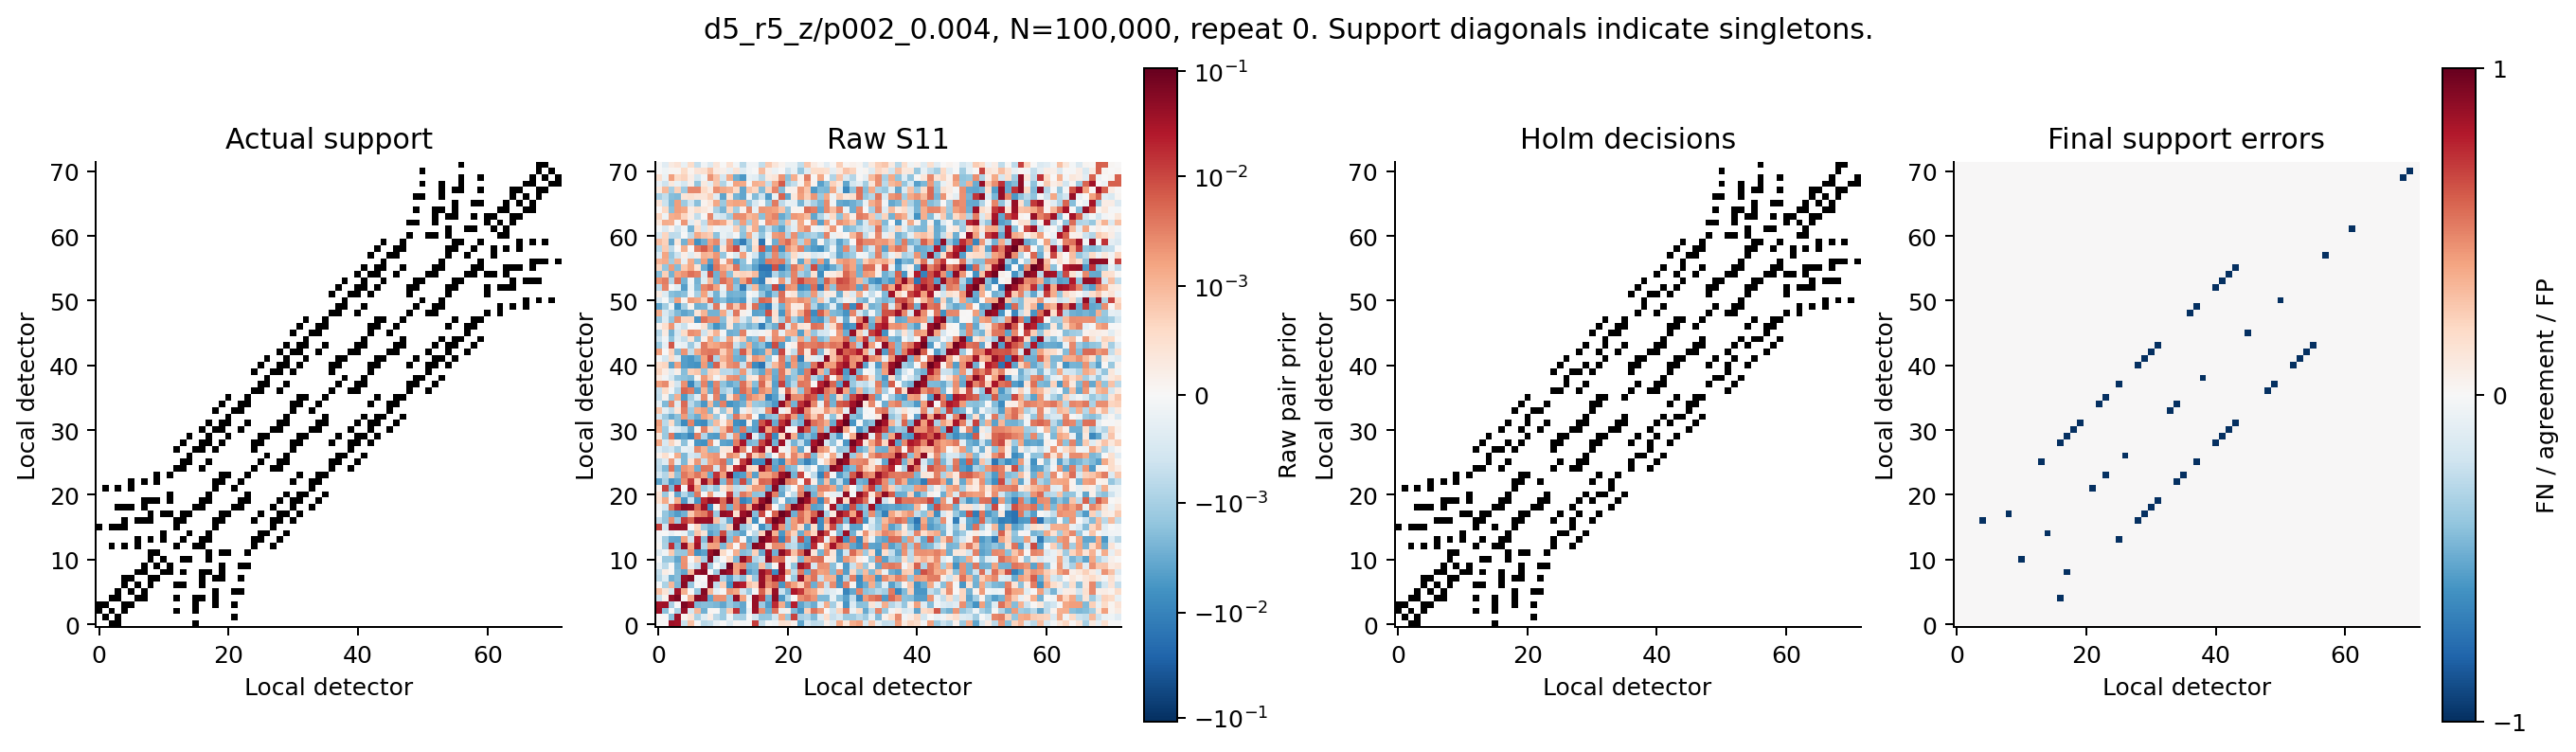

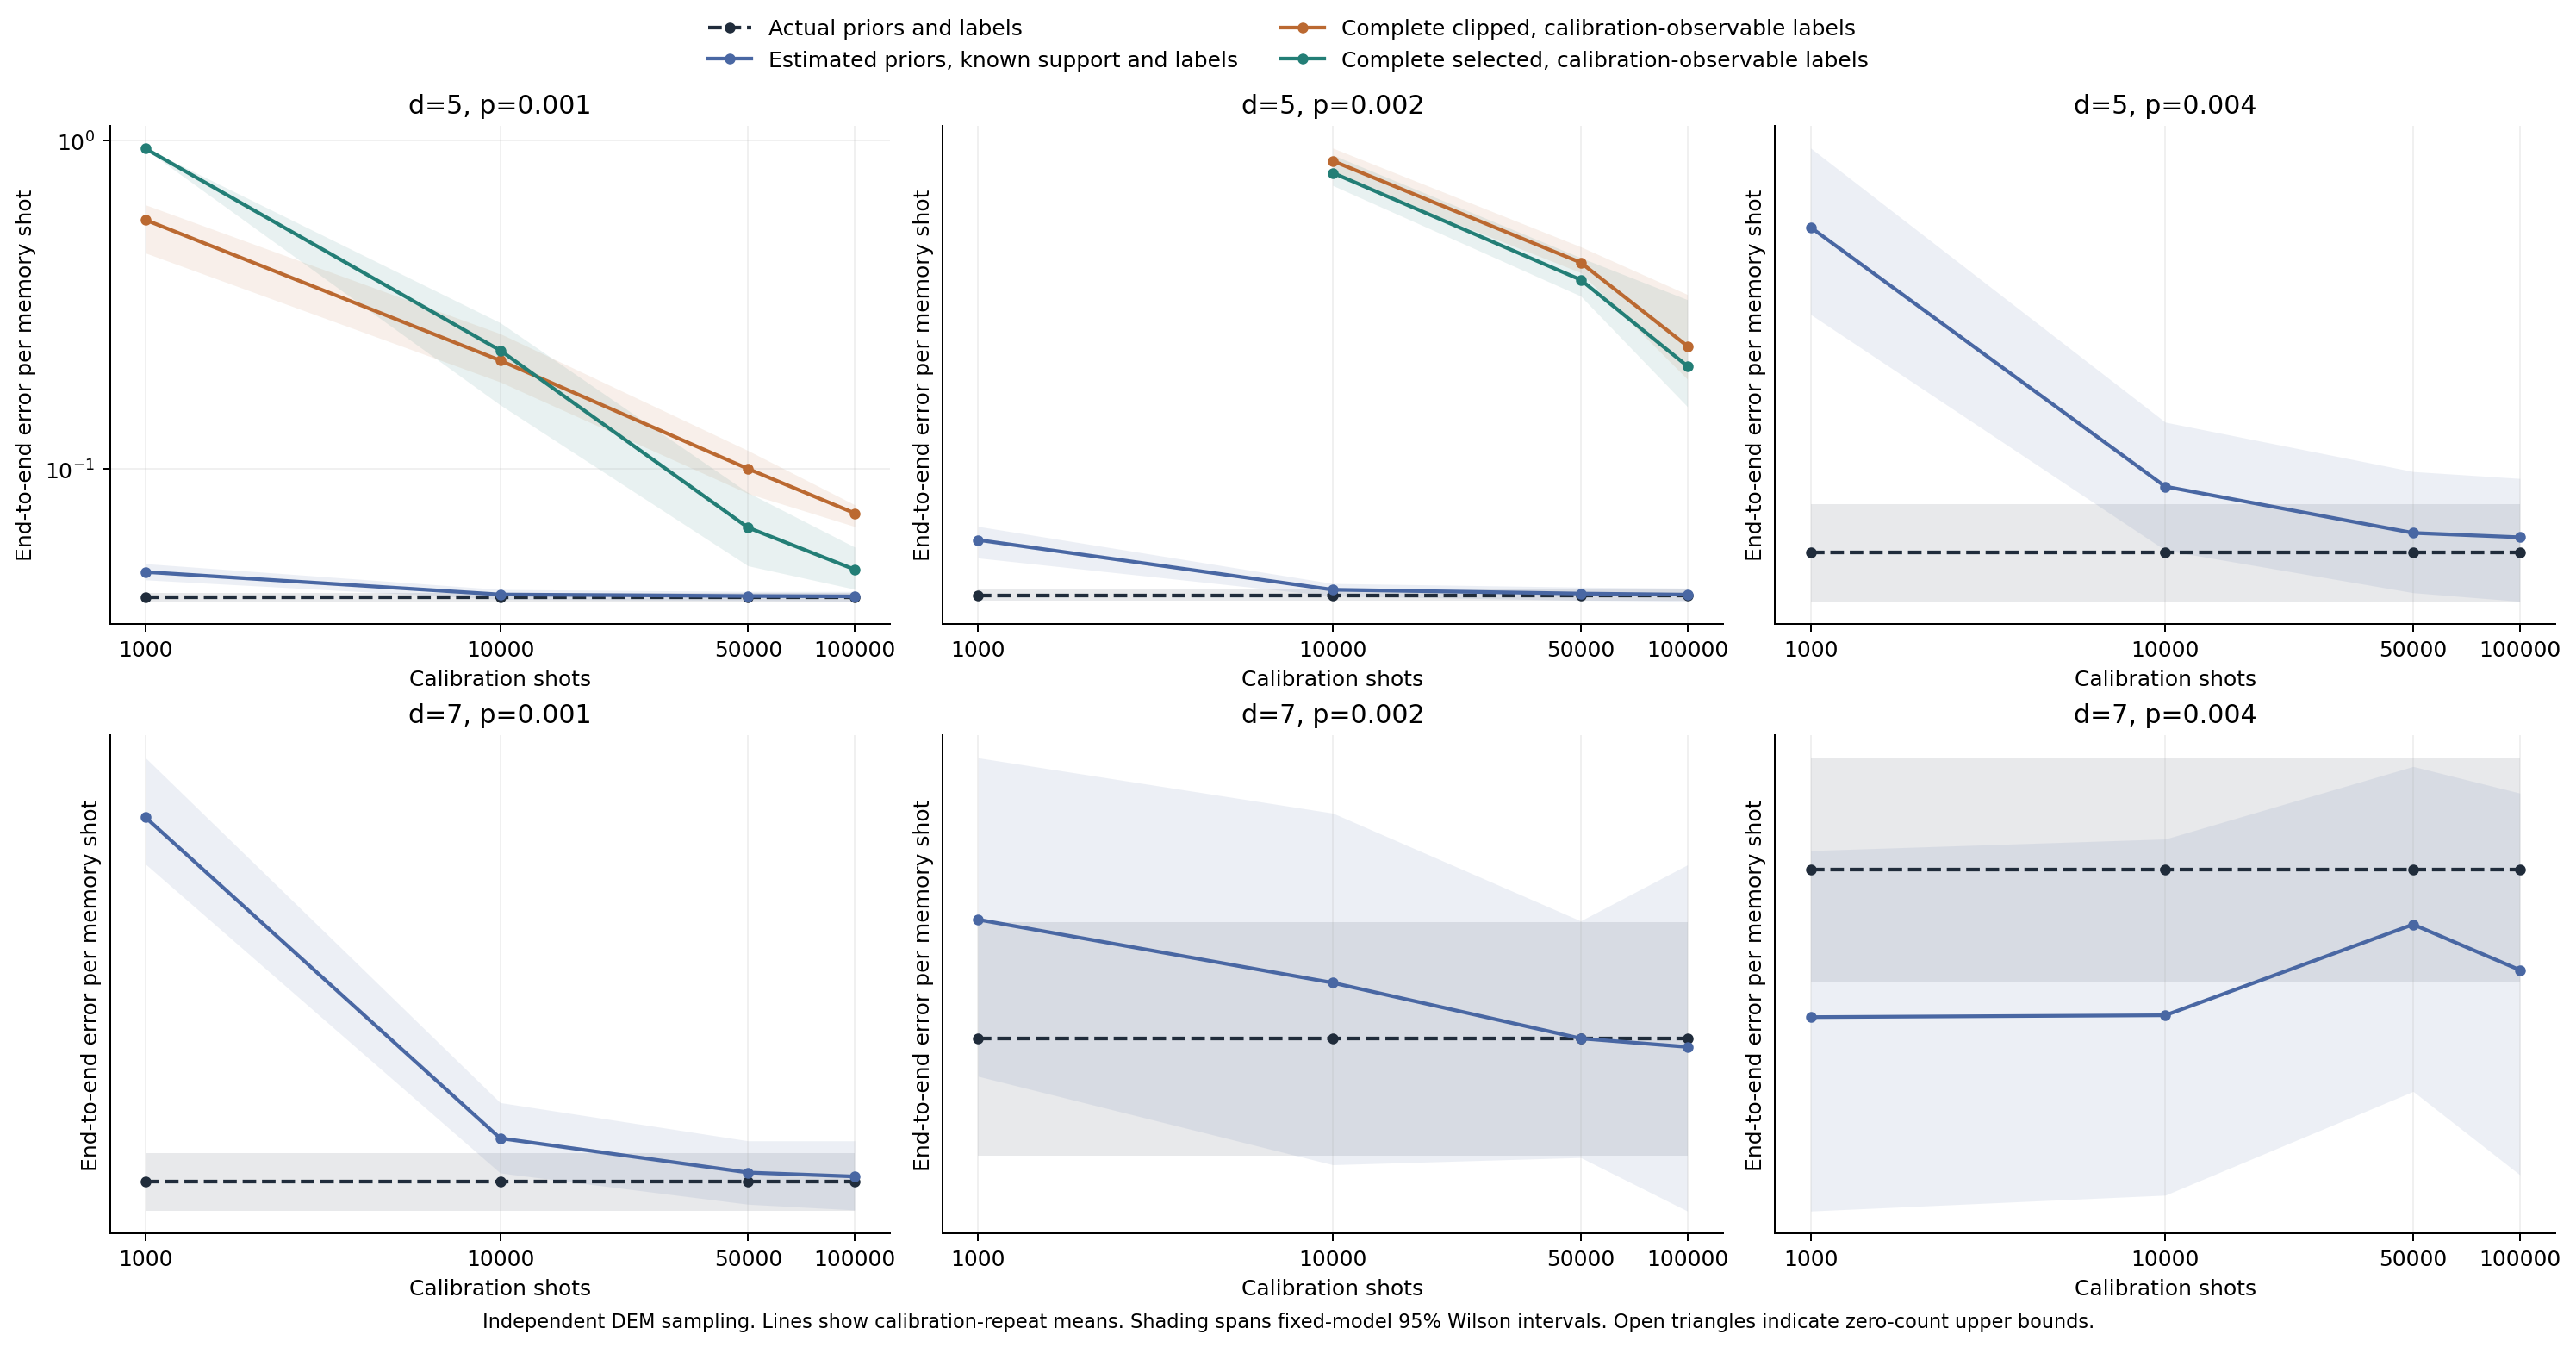

Figures ['ler_vs_physical_error.png', 'ler_vs_physical_error.pdf', 'ler_vs_calibration_shots.png', 'ler_vs_calibration_shots.pdf', 'support_vs_calibration_shots.png', 'support_vs_calibration_shots.pdf', 'prior_error_vs_calibration_shots.png', 'prior_error_vs_calibration_shots.pdf', 'label_error_vs_calibration_shots.png', 'label_error_vs_calibration_shots.pdf', 'support_matrix_comparison.png', 'support_matrix_comparison.pdf', 'raw_prior_histograms.png', 'raw_prior_histograms.pdf']
Output directory results/structure1


In [5]:
figures = experiment.plot_structure_stage(out)
for name in ('support_matrix_comparison.png', 'ler_vs_calibration_shots.png'):
    display(Image(filename=str(out / 'figures' / name)))
print('Figures', [path.name for path in figures])
print('Output directory', out.relative_to(root))
